In [165]:
from langgraph.graph import StateGraph ,START,END
from typing import TypedDict,Literal

In [166]:
class StudentSubject(TypedDict):
    math:int
    ml:int
    dp:int
    python:int
    sql:int
    attendance:int

    marks:str

    avg_sub:float
    avg_attendance:float

    average:float
    performance:str
    response:str


In [167]:
def show_marks(state:StudentSubject):
    subjects=f'{state['math']}+{state["ml"]}+{state["dp"]}+{state["python"]}+{state["sql"]}'
    return {'marks':subjects}



In [168]:
def total_average(state:StudentSubject):
    average_sub=((state['math']+state['ml']+state['dp']+state['python']+state['sql'])/5)*0.8+((state['attendance']*100/100)*0.2)

    
    return{'average':average_sub}

In [169]:
def performance(state:StudentSubject):
    if state["average"] >= 80:
      return {'response':"excellent"}

    elif state["average"] >= 60:
      return {'response':"improve"}

    else:
     return {'response':"need_support"}

In [170]:
graph=StateGraph(StudentSubject)

graph.add_node('show_marks',show_marks)
graph.add_node('total_average',total_average)
graph.add_node('performance', performance)
# graph.add_node('performance',avg_attendancee)

graph.add_edge(START,'show_marks')
graph.add_edge('show_marks', 'total_average')
graph.add_edge('total_average', 'performance')
# graph.add_edge('avg_attendancee','total_average')
graph.add_edge('performance',END)



workflow=graph.compile()


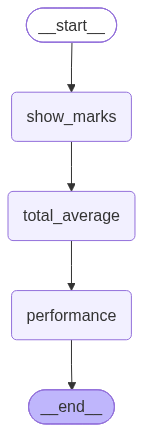

In [171]:
workflow

In [174]:
in_state={
        'math':70,
        'ml':90,
        'dp':90,
        'python':90,
        'sql':80,
        'attendance':85
}

In [179]:
workflow.invoke(in_state)

{'math': 70,
 'ml': 90,
 'dp': 90,
 'python': 90,
 'sql': 80,
 'attendance': 85,
 'marks': '70+90+90+90+80',
 'average': 84.2,
 'response': 'excellent'}